# 03 — Is finishing a repeatable skill, or mostly noise?

**The question.** A player who scores more than their chances were worth is said to
be a good finisher. Is that a property of the player that shows up again next
season, or is it mostly the residue of a good run?

**Why it matters.** It decides what a finishing number is *for*. If finishing
repeats, then goals minus expected goals is a scouting metric and a player with a
big positive number is worth paying more for. If it does not, then the same number
is a description of what already happened and a warning that it is about to stop —
and the thing worth paying for is whoever gets into good positions often, which is
a different player.

**The design.** Take every player who cleared a minutes floor in both complete
seasons, measure finishing in each, and see whether the two agree. The crucial part
is the **control**: the same players, the same source, the same two seasons, but
measuring something else — how often they shoot, and how good their chances are. If
those repeat and finishing does not, the difference is about finishing, not about
the data being noisy.

**Not prediction.** Everything here is measured on seasons already played, and
every claim is an association. Building something that forecasts a player's next
season, validated out of sample, is Part 3 (CLAUDE.md §7).

## How to read this

Every number is computed live from the dbt marts named in the next cell. The
notebook runs against whatever `GOLD_SNAPSHOT_DIR` points at — the full export
locally, the tiny synthetic fixture in CI — so the **committed outputs are the real
snapshot**.

The fixture holds a handful of invented players and cannot support a
season-to-season correlation. Rather than print a meaningless number there, the
cells below check the sample size and say so.

In [1]:
import sys
from pathlib import Path

# The repository's shared code lives in src/, next to this notebooks/ folder.
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from football_analytics import marts, viz
from football_analytics import stats as st

viz.apply_style()
pd.set_option("display.width", 200)

# Below this, a correlation says more about the sample than about football. It is
# also what keeps this notebook honest on the CI fixture.
MIN_SAMPLE = 30

m = marts.open_marts()
CITATION = m.citation()
print(CITATION)

dbt marts built from the Gold snapshot exported 2026-09-20T13:41:36+00:00, matches 2024-08-15 to 2026-09-19 (3,733 matches, 115,410 player events, 94,034 shots)


## 1. Defining finishing, and the two traps in it

**Penalties have to come out.** `fact_player_events.xg` includes them, so a
finishing number built from it is largely a statement about who takes penalties
(CLAUDE.md §5, trap 8). `mart_player_season` carries `np_goals_minus_npxg`, built
from the shots with `situation <> 'Penalty'`, and that is what is used throughout.

**A minutes floor is required.** A player with 200 minutes and one lucky goal reads
as the best finisher in Europe. The floor is a dbt var (`min_minutes`, default 900 —
ten full matches) and travels on every row so a chart can state it.

In [2]:
seasons = m.df(
    """
    SELECT understat_player_id, player_name, season, competition_code, primary_team_name,
           minutes, matches, shots, np_goals, npxg,
           np_goals_minus_npxg, np_goals_minus_npxg_per_90,
           npxg_per_90, np_goals_per_90, shots_per_90, min_minutes
    FROM mart_player_season
    WHERE meets_minutes_floor
      AND season IN ('2024/25', '2025/26')
    """
)

S1, S2 = "2024/25", "2025/26"
MEASURES = [
    "np_goals_minus_npxg_per_90", "npxg_per_90", "np_goals_per_90",
    "shots_per_90", "shots", "npxg", "np_goals", "np_goals_minus_npxg",
]

# Read the floor from the mart rather than from the filtered frame, so it is still
# reported when nothing clears it.
floor = int(m.df("SELECT max(min_minutes) AS floor FROM mart_player_season").floor.iloc[0])
print(f"minutes floor: {floor}")
print(f"player-seasons over the floor: {len(seasons):,}")

# One row per player, both seasons side by side. dropna keeps only the players who
# cleared the floor in *both* — the comparison has no meaning otherwise.
both = seasons.pivot_table(
    index=["understat_player_id", "player_name"], columns="season", values=MEASURES,
)
both.columns = [f"{name}__{season}" for name, season in both.columns]

# Every expected column is forced to exist even when no player qualifies. On the CI
# fixture nobody reaches 900 minutes, and without this the pivot comes back with no
# columns at all and the cells below fail on a missing key instead of reporting an
# empty sample — which is what they were written to do.
both = both.reindex(columns=[f"{name}__{s}" for name in MEASURES for s in (S1, S2)])
both = both.dropna().reset_index()

print(f"players clearing the floor in both seasons: {len(both):,}")
if len(both) < MIN_SAMPLE:
    print(f"\nFewer than {MIN_SAMPLE} — the sections below report that rather than "
          "estimating from it. This is the expected result on the CI fixture.")


minutes floor: 900
player-seasons over the floor: 3,160
players clearing the floor in both seasons: 1,022


### The trap the minutes floor does not fix

Finishing *per 90* is mechanically near zero for anyone who rarely shoots: a
centre-back with two shots a season cannot be far from their expected goals. So
sorting players by finishing per 90 does not sort them by finishing ability — it
sorts them by shot volume, with the low-volume players piled in the middle and the
attackers at both ends.

In [3]:
if len(both) >= MIN_SAMPLE:
    quintile = pd.qcut(
        both[f"np_goals_minus_npxg_per_90__{S1}"], 5,
        labels=["worst", "poor", "average", "good", "best"], duplicates="drop",
    )
    volume_by_group = both.groupby(quintile, observed=True).agg(
        players=("player_name", "size"),
        mean_finishing_per_90=(f"np_goals_minus_npxg_per_90__{S1}", "mean"),
        mean_npxg_per_90=(f"npxg_per_90__{S1}", "mean"),
        mean_shots=(f"shots__{S1}", "mean"),
    ).round(3)
    display(volume_by_group)
else:
    print(f"only {len(both)} players clear the floor in both seasons - too few to group")

,players,mean_finishing_per_90,mean_npxg_per_90,mean_shots
np_goals_minus_npxg_per_90__2024/25,,,,
worst,205,-0.102,0.239,38.595
poor,204,-0.034,0.113,24.848
average,259,-0.008,0.050,12.069
good,149,0.011,0.115,26.275
best,205,0.078,0.187,35.107


**Both tails are attackers and the middle is everyone else.** The best and worst
finishing groups take two to five times as many shots as the average group. That is
the shape of a measure dominated by volume, and it means two things for what
follows: the headline test is run on everyone, and then re-run on a **shot base** so
that finishing is measured where there is enough shooting to measure it.

## 2. Does finishing repeat, season to season?

The headline test, with three controls measured on exactly the same players.

In [4]:
# Lines are collected and printed once: consecutive print() calls get split into
# stdout chunks unpredictably, which makes an identical re-run produce a different
# notebook file.
report = [f"{S1} -> {S2}, players over {floor} minutes in both", ""]


def repeatability(label, column):
    """Season-to-season correlation for one per-90 measure, or a note if too small."""
    if len(both) < MIN_SAMPLE:
        report.append(f"  {label:34s} - only {len(both)} players; not estimated")
        return None
    estimate = st.correlation_ci(both[f"{column}__{S1}"], both[f"{column}__{S2}"])
    report.append(f"  {label:34s} r = {estimate}")
    return estimate


finishing = repeatability("finishing per 90 (npG - npxG)", "np_goals_minus_npxg_per_90")
report.append("  " + "-" * 72)
volume = repeatability("npxG per 90  (chance volume)", "npxg_per_90")
repeatability("shots per 90", "shots_per_90")
repeatability("non-penalty goals per 90", "np_goals_per_90")
print("\n".join(report))

2024/25 -> 2025/26, players over 900 minutes in both

  finishing per 90 (npG - npxG)      r = +0.095 (95% CI +0.009 to +0.177, n = 1,022), p = 0.002
  ------------------------------------------------------------------------
  npxG per 90  (chance volume)       r = +0.848 (95% CI +0.822 to +0.873, n = 1,022), p = 0.000
  shots per 90                       r = +0.903 (95% CI +0.890 to +0.915, n = 1,022), p = 0.000
  non-penalty goals per 90           r = +0.727 (95% CI +0.684 to +0.766, n = 1,022), p = 0.000


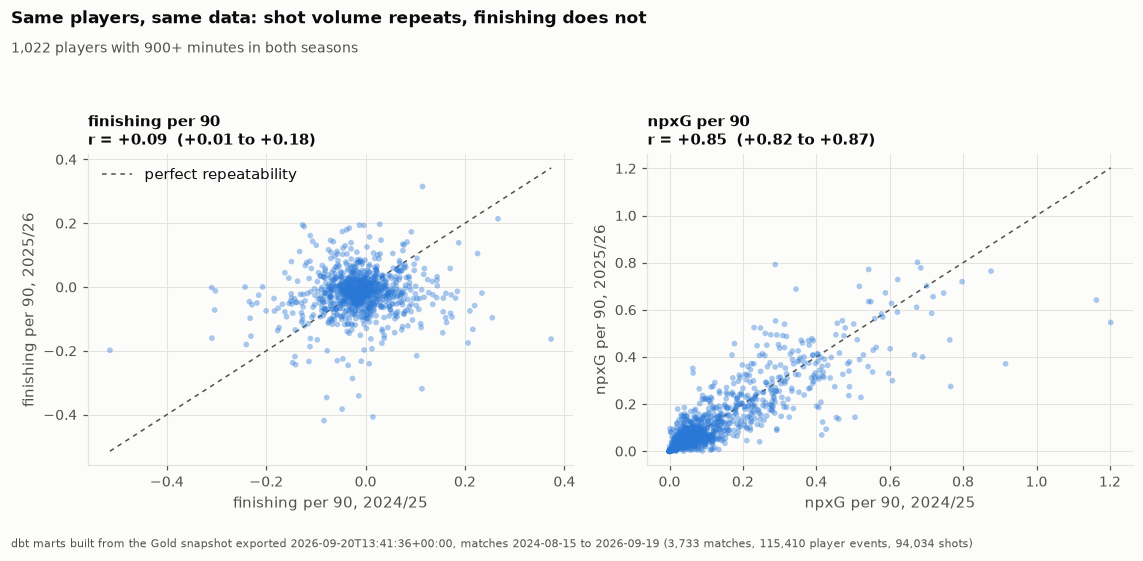

In [5]:
if len(both) >= MIN_SAMPLE:
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.8))

    panels = [
        (axes[0], "np_goals_minus_npxg_per_90", "finishing per 90", finishing),
        (axes[1], "npxg_per_90", "npxG per 90", volume),
    ]
    for ax, column, name, estimate in panels:
        x, y = both[f"{column}__{S1}"], both[f"{column}__{S2}"]
        ax.scatter(x, y, s=14, color=viz.ACCENT, alpha=0.4, edgecolor="none", zorder=3)

        # y = x, the line a perfectly repeatable measure would sit on.
        lo = min(x.min(), y.min())
        hi = max(x.max(), y.max())
        ax.plot([lo, hi], [lo, hi], color=viz.INK_MUTED, lw=1,
                ls=(0, (3, 3)), zorder=2, label="perfect repeatability")

        ax.set_xlabel(f"{name}, {S1}")
        ax.set_ylabel(f"{name}, {S2}")
        ax.set_title(f"{name}\nr = {estimate.value:+.2f}  "
                     f"({estimate.low:+.2f} to {estimate.high:+.2f})", fontsize=10)

    axes[0].legend(loc="upper left")
    fig.suptitle(
        "Same players, same data: shot volume repeats, finishing does not",
        x=0.005, ha="left", fontsize=11, fontweight="bold",
    )
    fig.text(0.005, 0.90, f"{len(both):,} players with {floor}+ minutes in both seasons",
             fontsize=9, color=viz.INK_MUTED)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    viz.annotate_source(axes[0], CITATION)
    plt.show()
else:
    print("not enough players to plot")

**The contrast is the finding.** The right-hand cloud hugs the diagonal: a
player who generated 0.4 npxG per 90 does it again. The left-hand cloud is a
shapeless blob around zero — last season's finishing barely locates this season's.

This is the strongest form the argument can take, because the two panels differ in
*nothing* except which quantity is measured. Same players, same seasons, same source,
same minutes floor. Whatever makes finishing unrepeatable is not a property of the
dataset.

## 3. On a proper shot base

Section 1 showed that finishing per 90 is dominated by volume, so the headline test
mixes players who take 100 shots with players who take five. Restricting to players
with real shooting volume in both seasons asks the fairer question — and lets
finishing be expressed per shot, which removes volume from the measure itself.

In [6]:
def restricted(minimum_npxg):
    """Players clearing the minutes floor and `minimum_npxg` npxG in both seasons."""
    subset = both[
        (both[f"npxg__{S1}"] >= minimum_npxg) & (both[f"npxg__{S2}"] >= minimum_npxg)
    ].copy()
    # Safe to divide as long as the threshold is positive, which every one used
    # below is: a player with npxG above zero has taken at least one shot.
    for season, tag in ((S1, "1"), (S2, "2")):
        subset[f"per_shot_{tag}"] = (
            subset[f"np_goals_minus_npxg__{season}"] / subset[f"shots__{season}"]
        )
        subset[f"ratio_{tag}"] = subset[f"np_goals__{season}"] / subset[f"npxg__{season}"]
    return subset


# Thresholds all start above zero, which is what makes the per-shot and ratio
# columns well defined: a player with no npxG has no shots to divide by.
measures = {
    "finishing per 90": (f"np_goals_minus_npxg_per_90__{S1}",
                         f"np_goals_minus_npxg_per_90__{S2}"),
    "finishing per shot": ("per_shot_1", "per_shot_2"),
    "npG / npxG": ("ratio_1", "ratio_2"),
    "npxG per 90 (control)": (f"npxg_per_90__{S1}", f"npxg_per_90__{S2}"),
}

rows = []
for threshold in (1, 5, 10):
    subset = restricted(threshold)
    row = {"npxG floor": threshold, "players": len(subset)}
    for name, (a, b) in measures.items():
        # Reported whenever a correlation is defined at all, with the player count
        # beside it. A wide interval says "this sample cannot answer the question"
        # more usefully than a blank does.
        if len(subset) >= 3:
            e = st.correlation_ci(subset[a], subset[b])
            row[name] = f"{e.value:+.2f} [{e.low:+.2f}, {e.high:+.2f}]"
        else:
            row[name] = "too few players"
    rows.append(row)

pd.DataFrame(rows).set_index("npxG floor")

,players,finishing per 90,finishing per shot,npG / npxG,npxG per 90 (control)
npxG floor,,,,,
1,585,"+0.08 [-0.01, +0.17]","+0.06 [-0.03, +0.15]","+0.03 [-0.06, +0.13]","+0.80 [+0.76, +0.84]"
5,133,"+0.19 [+0.04, +0.35]","+0.24 [+0.09, +0.38]","+0.24 [+0.08, +0.39]","+0.61 [+0.49, +0.72]"
10,24,"+0.02 [-0.34, +0.50]","+0.17 [-0.27, +0.65]","+0.10 [-0.28, +0.56]","+0.65 [+0.46, +0.86]"


**A hint, and not more than that.** The three thresholds do not tell one story.
At npxG ≥ 1 — 585 players, the most statistical power of the three — finishing does
**not** repeat: all three formulations sit between +0.03 and +0.08 with intervals
that include zero. At npxG ≥ 5 the estimates rise to +0.19 to +0.24 and clear zero.
At npxG ≥ 10 only two dozen players remain and the intervals span from strongly
negative to strongly positive.

One threshold out of three showing a nominally significant result, and the one with
the *most* players showing none, is not how a solid effect behaves. Read together,
the fair summary is that every estimate is small and positive (+0.02 to +0.24) and
that this sample cannot establish whether there is a real repeatable component or
not. What it can establish is an upper bound: whatever is there is small enough that
two complete seasons of the big five leagues cannot pin it down.

The control column is the contrast that matters. npxG per 90 repeats at +0.61 to
+0.80 in the very same players and subsets, with tight intervals throughout. The
question is not whether these players are measurable — they are — but whether
finishing is a stable thing to measure.

## 4. So what should you look at to know who will score?

The practical form of the question. Take next season's non-penalty goals per 90 as
the outcome, and ask which of last season's numbers points at it.

In [7]:
if len(both) >= MIN_SAMPLE:
    target = both[f"np_goals_per_90__{S2}"]
    lines = [
        f"  {label:32s} r = {st.correlation_ci(both[column], target)}"
        for label, column in [
            ("last season's finishing per 90", f"np_goals_minus_npxg_per_90__{S1}"),
            ("last season's npxG per 90", f"npxg_per_90__{S1}"),
            ("last season's npG per 90", f"np_goals_per_90__{S1}"),
        ]
    ]
    delta = st.paired_correlation_difference_ci(
        both[f"npxg_per_90__{S1}"], both[f"np_goals_minus_npxg_per_90__{S1}"], target
    )
    lines += ["", f"  npxG per 90 over finishing:  Δr = {delta}",
              f"  distinguishable from zero: {delta.excludes_zero}"]
    print("\n".join(lines))
else:
    print(f"only {len(both)} players; not estimated")

  last season's finishing per 90   r = -0.088 (95% CI -0.175 to +0.000, n = 1,022), p = 0.005
  last season's npxG per 90        r = +0.777 (95% CI +0.738 to +0.811, n = 1,022), p = 0.000
  last season's npG per 90         r = +0.727 (95% CI +0.684 to +0.766, n = 1,022), p = 0.000

  npxG per 90 over finishing:  Δr = +0.865 (95% CI +0.770 to +0.960, n = 1,022)
  distinguishable from zero: True


**Chance volume wins overwhelmingly, and finishing points the wrong way.**
Last season's npxG per 90 tracks next season's goals at around r = 0.78. Last
season's finishing is *slightly negative*, and the gap between the two is enormous
and nowhere near zero.

The negative sign is the volume trap of section 1 showing up again rather than
anything mystical: the players with the largest positive finishing residuals are
disproportionately high-volume attackers who had a hot season, and what follows is
a return to their own normal. Read it as "finishing carries no useful information
about next season's scoring rate", not as "good finishers get worse".

## 5. What happens to last season's best finishers?

Directly, rather than through a correlation.

In [8]:
if len(both) >= MIN_SAMPLE:
    both["finishing_group"] = pd.qcut(
        both[f"np_goals_minus_npxg_per_90__{S1}"], 5,
        labels=["worst", "poor", "average", "good", "best"], duplicates="drop",
    )
    summary = both.groupby("finishing_group", observed=True).agg(
        players=("player_name", "size"),
        finishing_s1=(f"np_goals_minus_npxg_per_90__{S1}", "mean"),
        finishing_s2=(f"np_goals_minus_npxg_per_90__{S2}", "mean"),
        npxg_per_90_s1=(f"npxg_per_90__{S1}", "mean"),
    ).round(3)
    display(summary)

    best = both[both.finishing_group == "best"]
    worst = both[both.finishing_group == "worst"]
    best_shift = st.mean_difference_ci(
        best[f"np_goals_minus_npxg_per_90__{S1}"], best[f"np_goals_minus_npxg_per_90__{S2}"]
    )
    worst_shift = st.mean_difference_ci(
        worst[f"np_goals_minus_npxg_per_90__{S1}"], worst[f"np_goals_minus_npxg_per_90__{S2}"]
    )
    print("\n".join([
        f"best finishers  {S1} -> {S2}: {best_shift}",
        f"worst finishers {S1} -> {S2}: {worst_shift}",
    ]))
else:
    print(f"only {len(both)} players; not grouped")

,players,finishing_s1,finishing_s2,npxg_per_90_s1
finishing_group,,,,
worst,205,-0.102,-0.030,0.239
poor,204,-0.034,-0.017,0.113
average,259,-0.008,-0.010,0.050
good,149,0.011,-0.019,0.115
best,205,0.078,-0.016,0.187


best finishers  2024/25 -> 2025/26: -0.094 (95% CI -0.108 to -0.081, n = 205)
worst finishers 2024/25 -> 2025/26: +0.072 (95% CI +0.060 to +0.084, n = 205)


**Both tails land on essentially zero.** Last season's best finishers finish at
about the average this season; last season's worst do the same, from the other
direction. Both movements are far clear of zero.

As in notebook 02, part of this is regression to the mean as a statistical
inevitability — select the extremes of a noisy measure and they are less extreme
next time whatever the truth. That caveat does not rescue finishing as a scouting
metric, though: the section 3 result puts a ceiling on how much signal is there to
regress towards.

## The answer

**Finishing is mostly noise. Whatever repeatable component exists is too small for
two seasons of data to pin down.**

Across 1,022 players who played at least 900 minutes in both complete big-5 seasons,
non-penalty finishing per 90 repeats from one season to the next at r ≈ 0.10 — about
1% of the variation. The same players' shot volume repeats at r ≈ 0.90 and their
npxG per 90 at r ≈ 0.85, so this is not a noisy dataset: it is a noisy quantity.

Restricting to players with real shooting volume was meant to settle whether a
skill hides underneath, and it does not. The estimates are small and positive at
every threshold, but only the middle one (npxG ≥ 5, 133 players) clears zero, while
the threshold with the most players (npxG ≥ 1, 585 players) does not. That pattern
is consistent with a very small real effect and equally consistent with none, and
the honest conclusion is that this sample cannot distinguish them.

**For anything forward-looking, chance volume is the number to read.** Last
season's npxG per 90 tracks next season's non-penalty goals per 90 at r ≈ 0.78,
while last season's finishing is very slightly negative, and the difference between
them is decisive. Last season's best finishers regress to roughly average.

**So a big positive finishing number is mostly a description of a season that has
already happened**, and it carries almost nothing about the next one.

### Caveats

- **Two seasons is one comparison.** Every repeatability figure here rests on a
  single year-to-year pairing. The section 3 estimates are the clearest case for
  wanting a third: one threshold clears zero and its neighbours do not, which is
  what both a small real effect and pure chance look like at this sample size.
- **The minutes floor selects on survival.** Players who cleared 900 minutes in both
  seasons kept their place — plausibly a group that finished well enough not to be
  dropped, which if anything works *against* finding finishing unrepeatable.
- **Finishing per 90 is confounded by volume**, as section 1 shows; the per-shot and
  ratio versions in section 3 are the better measures, and within each threshold the
  three formulations agree closely — it is *across* thresholds that they disagree.
- **The npxG ≥ 10 row is underpowered** at two dozen players, and is reported with
  its very wide interval rather than hidden, because that interval is the finding
  there: two seasons cannot answer the question for regular starting forwards alone.
- **This is Understat's xG model.** "More goals than expected" means more than that
  model expected; a systematic bias in it — against a particular shot type, say —
  would appear here as a player trait. Nothing in Gold can separate the two.
- **Nothing here is causal**, and none of it is a forecast. A player-level
  projection, trained and validated out of sample, is Part 3.
- **npxG is rebuilt from `fact_shots`** because Gold has no non-penalty xG per player
  (§5 trap 8), over shots deduplicated by shape (trap 14). Both reconstructions are
  checked against Understat's own totals by dbt tests on every build.